# Satellite collision risk evaluator — development and training

Use this notebook to develop and evaluate the model. Training data are local to this folder;
test telemetry is read from `../prediction/test_data.csv`. Experimental models, encoders,
evaluation reports, and dashboard exports are written to this folder's `artifacts/`.

From the repository root, prepare the separate development environment:

```bash
python3 -m venv development/.venv
development/.venv/bin/python -m pip install -r development/requirements-dev.lock.txt
```

Open JupyterLab with the configured interpreter and local OpenMP runtime:

```bash
development/.venv/bin/python development/execute_notebook.py --lab
```

Or execute and save all cells headlessly:

```bash
development/.venv/bin/python development/execute_notebook.py
```

Training leaves the deployed model in `../prediction/artifacts/` unchanged. See this folder's
README for copying a reviewed model and encoder into the prediction workflow.


## Prediction contract and distance units

- Target: the **same row's** `risk` value; it is already logarithmic.
- Inputs: exactly the 12 requested source features, including `event_id`.
- Test protection: drop `risk`, `max_risk_estimate`, and `max_risk_scaling` before inference;
  no test targets are used for fitting, early stopping, scoring, or model selection.
- The supplied files match the [ESA Kelvins dataset](https://kelvins.esa.int/collision-avoidance-challenge/data/),
  whose documentation specifies `miss_distance` in **metres**, relative speed in m/s, and
  `time_to_tca` in days. Classification converts metres to kilometres.
- Export every telemetry row in input order. A second CSV selects the latest available
  telemetry row per event, using the minimum `time_to_tca`.

**Target horizon:** the original ESA competition predicts an event's final risk from earlier
messages. This implementation follows the requested row-level target. Removing test target
columns prevents target leakage; it does not turn a row-level regressor into a final-TCA
forecaster. No future rows are aggregated into the feature set.

The tier rules below are the policy specified in the prompt; this notebook does not establish
that the complete three-tier policy is a universal NASA/ESA standard.


In [1]:
from pathlib import Path
import json
import os
import sys
import subprocess

PROJECT_ROOT = Path.cwd().resolve()
if (PROJECT_ROOT / "development" / "collision_risk.py").exists():
    PROJECT_ROOT = PROJECT_ROOT / "development"
if not (PROJECT_ROOT / "collision_risk.py").exists():
    raise FileNotFoundError("Open this notebook from the repository root or development/.")
sys.path.insert(0, str(PROJECT_ROOT))
# Keep optional plotting caches within the writable project directory.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from collision_risk import (
    FEATURES, FORBIDDEN_TEST_COLUMNS, TIERS, SAFE, ELEVATED, CRITICAL,
    TrainingConfig, FeatureEncoder, classify_risk, require_columns,
    load_train_data, load_test_data, evaluate_model, fit_final_model,
    dashboard_predictions, latest_event_predictions, save_artifacts,
)
import xgboost

pd.set_option("display.max_columns", 20)
print({"python": sys.version.split()[0], "pandas": pd.__version__,
       "numpy": np.__version__, "xgboost": xgboost.__version__})


Matplotlib is building the font cache; this may take a moment.


{'python': '3.13.7', 'pandas': '3.1.0', 'numpy': '2.5.4', 'xgboost': '3.4.1'}


## Configuration

The histogram tree builder uses bounded CPU parallelism. Early stopping selects the boosting
budget on validation events, and an untouched set of holdout events measures generalization.
The final model is then refitted on all labelled training rows at that fixed budget.
Use `distance_unit="km"` only if replacing the supplied CSVs with kilometre-valued telemetry.


In [2]:
TRAIN_PATH = PROJECT_ROOT / "train_data.csv"
TEST_PATH = PROJECT_ROOT.parent / "prediction" / "test_data.csv"
OUTPUT_DIR = PROJECT_ROOT / "artifacts"

config = TrainingConfig(
    random_state=42,
    max_estimators=1600,
    early_stopping_rounds=80,
    max_depth=7,
    learning_rate=0.04,
    distance_unit="m",
)
print(config)
print("Allowed source features:", list(FEATURES))


TrainingConfig(random_state=42, holdout_fraction=0.2, validation_fraction=0.2, max_estimators=1600, early_stopping_rounds=80, learning_rate=0.04, max_depth=7, n_jobs=8, distance_unit='m')
Allowed source features: ['event_id', 'time_to_tca', 'miss_distance', 'relative_speed', 'relative_position_r', 'relative_position_t', 'relative_position_n', 'c_object_type', 'c_sigma_r', 't_sigma_r', 'F10', 'AP']


## Load training data and explicitly sanitize test data

Only approved inputs and the training target are loaded from the 103-column training CSV.
The test cell below visibly drops all three forbidden fields. The script's `load_test_data()`
performs the same sanitization and is covered by tests. Existing numeric event IDs are
independently numbered across files: do not join train and test on `event_id`.


In [3]:
train_data = load_train_data(TRAIN_PATH)

# Read relevant columns, then EXPLICITLY REMOVE all forbidden test fields.
test_data = pd.read_csv(
    TEST_PATH,
    usecols=lambda name: name in (*FEATURES, *FORBIDDEN_TEST_COLUMNS),
)
test_data = test_data.drop(columns=list(FORBIDDEN_TEST_COLUMNS), errors="ignore")
require_columns(test_data, FEATURES)
test_data = test_data.loc[:, list(FEATURES)].copy()

assert not set(FORBIDDEN_TEST_COLUMNS).intersection(test_data.columns)
assert list(test_data.columns) == list(FEATURES)
assert list(train_data.columns) == [*FEATURES, "risk"]
assert train_data["risk"].le(0).all(), "risk must already be log10(Pc)"
print(f"Training rows: {len(train_data):,}; test rows: {len(test_data):,}")
display(pd.DataFrame({
    "rows": [len(train_data), len(test_data)],
    "events": [train_data.event_id.nunique(), test_data.event_id.nunique()],
}, index=["train", "sanitized_test"]))
display(test_data.head())


Training rows: 162,634; test rows: 24,484


,rows,events
train,162634,13154
sanitized_test,24484,2167


,event_id,time_to_tca,miss_distance,relative_speed,relative_position_r,relative_position_t,relative_position_n,c_object_type,c_sigma_r,t_sigma_r,F10,AP
0,0,6.842095,31816.0,7929.0,-365.5,26967.0,16880.6,UNKNOWN,212.775210,7.414544,76.0,11.0
1,0,6.571818,31095.0,7929.0,-361.8,26356.6,16497.2,UNKNOWN,212.758643,7.413035,75.0,9.0
2,0,6.112986,32202.0,7929.0,-370.7,27294.4,17085.1,UNKNOWN,212.784398,7.834560,75.0,9.0
3,0,5.921955,32878.0,7929.0,-376.3,27867.5,17443.8,UNKNOWN,212.793280,7.353785,75.0,9.0
4,0,2.228761,32792.0,7929.0,-375.6,27793.8,17399.4,UNKNOWN,212.798144,5.833502,71.0,4.0


,train_missing,test_missing
event_id,0,0
time_to_tca,0,0
miss_distance,0,0
relative_speed,0,0
relative_position_r,0,0
relative_position_t,0,0
relative_position_n,0,0
c_object_type,0,0
c_sigma_r,11,6
t_sigma_r,0,0


,risk
count,162634.000000
mean,-19.340603
std,10.011641
min,-30.000000
1%,-30.000000
50%,-17.870632
90%,-6.576148
99%,-4.480784
max,-1.442854


Train Pc >= 1e-4: 716
Train targets at the -30 floor: 67240
Test time_to_tca range (days): 2.000213078703704 6.993168715277778


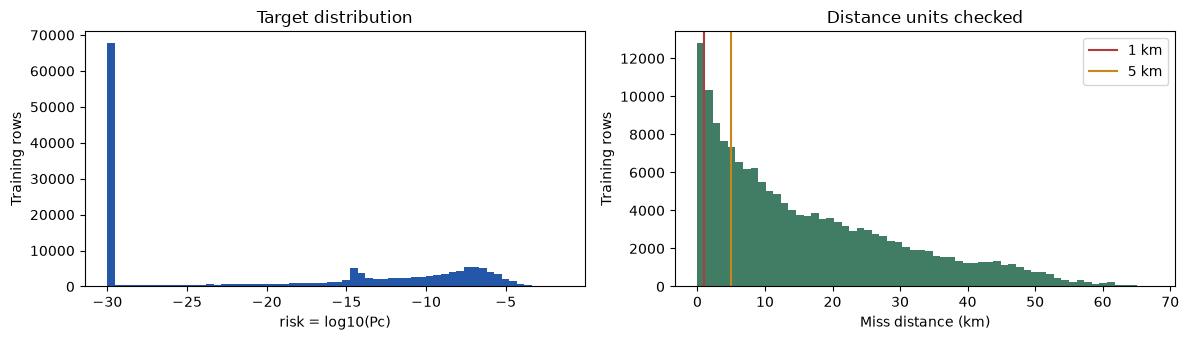

In [4]:
missingness = pd.DataFrame({
    "train_missing": train_data.loc[:, list(FEATURES)].isna().sum(),
    "test_missing": test_data.isna().sum(),
})
display(missingness)
display(train_data["risk"].describe(percentiles=[0.01, 0.5, 0.9, 0.99]).to_frame())
print("Train Pc >= 1e-4:", int(train_data["risk"].ge(-4).sum()))
print("Train targets at the -30 floor:", int(train_data["risk"].eq(-30).sum()))
print("Test time_to_tca range (days):", test_data.time_to_tca.min(), test_data.time_to_tca.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(train_data["risk"], bins=60, color="#2457a7")
axes[0].set(xlabel="risk = log10(Pc)", ylabel="Training rows", title="Target distribution")
axes[1].hist(train_data["miss_distance"] / 1000, bins=60, color="#417d65")
axes[1].axvline(1, color="#b33a3a", label="1 km")
axes[1].axvline(5, color="#c88718", label="5 km")
axes[1].set(xlabel="Miss distance (km)", ylabel="Training rows", title="Distance units checked")
axes[1].legend()
fig.tight_layout()
plt.show()


## Deterministic operational tiers

Evaluate the highest-priority matching rule first. Critical overrides Elevated wherever the
conditions overlap. Exactly 1.0 and 5.0 km belong to the Elevated distance band.

| Priority | Tier | Rule |
|---|---|---|
| 1 | Critical (Maneuver Required) | predicted risk $\ge -4$ **or** distance $<1$ km |
| 2 | Elevated risk | $-6\le$ predicted risk $<-4$ **or** $1\le$ distance $\le5$ km |
| 3 | Safe | predicted risk $<-6$ **and** distance $>5$ km |

The function compares log-risk directly: `risk >= -4` is equivalent to `Pc >= 1e-4`,
and avoids numerical underflow in very small probabilities. `Pc = 10**predicted_risk` is
available whenever a probability is needed for display. Nonfinite risks, missing distances,
and negative distances raise errors rather than producing a misleading tier.


In [5]:
boundary_examples = pd.DataFrame({
    "predicted_risk": [-7, -6, -4, -7, -7, -7, -5],
    "miss_distance_km": [6, 6, 6, 5, 1, 0.999, 0.5],
    "expected": [SAFE, ELEVATED, CRITICAL, ELEVATED, ELEVATED, CRITICAL, CRITICAL],
})
boundary_examples["risk_tier"] = classify_risk(
    boundary_examples.predicted_risk,
    boundary_examples.miss_distance_km,
    distance_unit="km",
)
assert boundary_examples.risk_tier.equals(boundary_examples.expected)
display(boundary_examples)

# Execute the reusable behavioral tests before the expensive training cells.
checks = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests"],
    cwd=PROJECT_ROOT, capture_output=True, text=True,
)
print(checks.stdout)
if checks.returncode:
    print(checks.stderr)
checks.check_returncode()


,predicted_risk,miss_distance_km,expected,risk_tier
0,-7,6.000,Safe,Safe
1,-6,6.000,Elevated risk,Elevated risk
2,-4,6.000,Critical (Maneuver Required),Critical (Maneuver Required)
3,-7,5.000,Elevated risk,Elevated risk
4,-7,1.000,Elevated risk,Elevated risk
5,-7,0.999,Critical (Maneuver Required),Critical (Maneuver Required)
6,-5,0.500,Critical (Maneuver Required),Critical (Maneuver Required)


..........................................                               [100%]
42 passed in 2.42s



## Train and assess generalization on unseen events

`GroupShuffleSplit` assigns approximately 64% / 16% / 20% of **events** to fit / early stopping /
held-out assessment. Multiple CDMs from one event never cross those partitions. This is an
unseen-event holdout, not a calendar-based backtest: absolute encounter dates are unavailable.

The categorical encoder learns its vocabulary on the fit partition only. Unseen object types
are accepted; missing numeric values use XGBoost's learned missing-value branches. All 12
source features remain included as requested. `event_id` is an arbitrary identifier, so its
value as a predictor should be revisited in later experiments with event IDs removed.

RMSE and MAE are measured in **log10(Pc)** units and compared with a constant mean baseline.
The holdout is never used for early stopping or repeated hyperparameter selection. A separate
holdout score for CDMs more than two days from TCA reflects the supplied test horizon.


In [6]:
evaluation = evaluate_model(train_data, config)
metrics = evaluation["metrics"]
best_rounds = metrics["selected_boosting_rounds"]

partitions = evaluation["partitions"]
event_sets = {name: set(train_data.iloc[idx].event_id) for name, idx in partitions.items()}
assert event_sets["fit"].isdisjoint(event_sets["validation"])
assert event_sets["fit"].isdisjoint(event_sets["holdout"])
assert event_sets["validation"].isdisjoint(event_sets["holdout"])
display(pd.DataFrame(metrics["partitions"]).T)
display(pd.DataFrame({
    "XGBoost": metrics["holdout_xgboost"],
    "Mean baseline": metrics["holdout_mean_baseline"],
}).T)
print("Selected boosting rounds:", best_rounds)
if best_rounds == config.max_estimators:
    print("Training reached the configured boosting budget; early stopping did not shorten it.")
print("Early-CDM holdout:", metrics.get("holdout_time_to_tca_gt_2_days"))


,rows,events
fit,104230,8418
validation,26366,2105
holdout,32038,2631


,rmse_log10_pc,mae_log10_pc,r2
XGBoost,5.723389,4.028133,0.672953
Mean baseline,10.008402,9.485998,-0.000076


Selected boosting rounds: 356
Early-CDM holdout: {'rows': 21944, 'rmse_log10_pc': 5.878837095239745, 'mae_log10_pc': 4.282913839520556, 'r2': 0.6213468987099764}


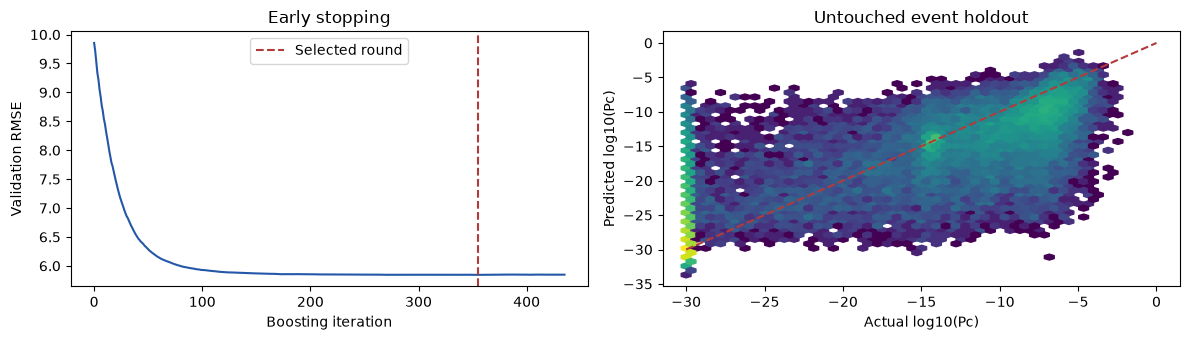

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
validation_curve = evaluation["model"].evals_result()["validation_0"]["rmse"]
axes[0].plot(validation_curve, color="#2457a7")
axes[0].axvline(best_rounds - 1, color="#b33a3a", linestyle="--", label="Selected round")
axes[0].set(xlabel="Boosting iteration", ylabel="Validation RMSE", title="Early stopping")
axes[0].legend()
axes[1].hexbin(evaluation["holdout_actual"], evaluation["holdout_prediction"],
               gridsize=45, mincnt=1, bins="log", cmap="viridis")
axes[1].plot([-30, 0], [-30, 0], color="#b33a3a", linestyle="--")
axes[1].set(xlabel="Actual log10(Pc)", ylabel="Predicted log10(Pc)", title="Untouched event holdout")
fig.tight_layout()
plt.show()


## Tier and probability-threshold diagnostics

The reference tier combines the observed training target with that row's distance.
A distance below 1 km creates a Critical tier even if the probability prediction is poor.
Therefore probability-only precision and recall at both 1e-6 and 1e-4 are reported separately.
Inspect these metrics before treating tier accuracy as evidence of probability prediction quality.
The large -30 target floor and rare high-probability cases are also visible above.


In [8]:
display(pd.DataFrame(metrics["tier_report"]).T)
display(pd.DataFrame(metrics["tier_confusion_matrix"], index=pd.Index(TIERS, name="actual"),
                     columns=pd.Index(TIERS, name="predicted")))
display(pd.DataFrame({
    "Pc >= 1e-6": metrics["probability_only_risk_ge_-6"],
    "Pc >= 1e-4": metrics["probability_only_risk_ge_-4"],
}).T)


,precision,recall,f1-score,support
Safe,0.967811,0.998042,0.982694,22986.000000
Elevated risk,0.986438,0.882603,0.931636,6593.000000
Critical (Maneuver Required),0.993018,0.983327,0.988149,2459.000000
accuracy,0.973157,0.973157,0.973157,0.973157
macro avg,0.982423,0.954657,0.967493,32038.000000
weighted avg,0.973579,0.973157,0.972606,32038.000000


predicted,Safe,Elevated risk,Critical (Maneuver Required)
actual,,,
Safe,22941,45,0
Elevated risk,757,5819,17
Critical (Maneuver Required),6,35,2418


,precision,recall,f1,actual_positive_rows,predicted_positive_rows
Pc >= 1e-6,0.636522,0.180207,0.280890,2031.0,575.0
Pc >= 1e-4,0.083333,0.036232,0.050505,138.0,60.0


## Refit the final regressor and predict sanitized test inputs

The final refit uses all training labels and the selected tree count. `predicted_risk` remains
in log space; its upper bound is clipped to zero so the implied probability cannot exceed one.
Test rows are not deduplicated, reordered, or joined with the training data.


In [9]:
model, encoder = fit_final_model(train_data, config, best_rounds)

assert not set(FORBIDDEN_TEST_COLUMNS).intersection(test_data.columns)
assert list(test_data.columns) == list(FEATURES)
dashboard_data = dashboard_predictions(model, encoder, test_data,
                                       distance_unit=config.distance_unit)
latest_event_data = latest_event_predictions(dashboard_data, test_data)

assert list(dashboard_data.columns) == ["event_id", "predicted_risk", "risk_tier"]
assert len(dashboard_data) == len(test_data)
assert dashboard_data.event_id.tolist() == test_data.event_id.tolist()
assert np.isfinite(dashboard_data.predicted_risk).all()
assert dashboard_data.predicted_risk.le(0).all()
assert set(dashboard_data.risk_tier).issubset(TIERS)
assert latest_event_data.event_id.is_unique
assert len(latest_event_data) == test_data.event_id.nunique()
display(dashboard_data.head(10))
display(dashboard_data.risk_tier.value_counts().rename("telemetry_rows").to_frame())
print(f"Per-row export: {len(dashboard_data):,}; latest-event export: {len(latest_event_data):,}")


,event_id,predicted_risk,risk_tier
0,0,-7.059641,Safe
1,0,-7.191969,Safe
2,0,-7.423293,Safe
3,0,-7.374438,Safe
4,0,-13.257710,Safe
5,1,-12.975824,Critical (Maneuver Required)
6,1,-13.325657,Critical (Maneuver Required)
7,2,-7.361787,Safe
8,2,-7.627353,Safe
9,2,-8.478148,Safe


,telemetry_rows
risk_tier,
Safe,16630
Elevated risk,5669
Critical (Maneuver Required),2185


Per-row export: 24,484; latest-event export: 2,167


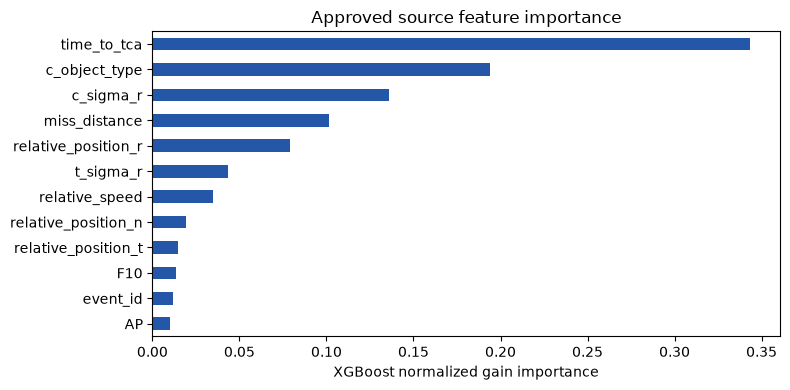

In [10]:
importance = pd.Series(model.feature_importances_, index=encoder.output_columns_)
# Aggregate category indicators back to their one approved source feature.
source_importance = importance.groupby(
    lambda name: "c_object_type" if name.startswith("c_object_type_") else name
).sum().reindex(FEATURES).sort_values()
ax = source_importance.plot.barh(figsize=(8, 4), color="#2457a7")
ax.set(xlabel="XGBoost normalized gain importance", title="Approved source feature importance")
plt.tight_layout()
plt.show()


## Export dashboard datasets and a reusable model

`dashboard_predictions.csv` contains exactly the requested three fields, one row per test CDM.
`dashboard_latest_events.csv` contains the same fields, one row per event selected from its
latest available CDM. It is an optional current-event UI view, not a forecast of final-event risk.

The encoder metadata and model are saved separately so future sanitized telemetry can be
predicted without refitting. Evaluation metadata records configuration, units, feature contract,
holdout performance, and chosen boosting rounds.


In [11]:
save_artifacts(OUTPUT_DIR, model, encoder, dashboard_data, latest_event_data, metrics, config)

# Verify the saved model+encoder reproduce the exported predictions.
restored_model = xgboost.XGBRegressor()
restored_model.load_model(OUTPUT_DIR / "collision_risk_model.ubj")
restored_encoder = FeatureEncoder.load(OUTPUT_DIR / "feature_encoder.json")
restored_predictions = dashboard_predictions(restored_model, restored_encoder, test_data,
                                               distance_unit=config.distance_unit)
pd.testing.assert_frame_equal(dashboard_data, restored_predictions)

csv_check = pd.read_csv(OUTPUT_DIR / "dashboard_predictions.csv")
pd.testing.assert_frame_equal(csv_check, dashboard_data, check_exact=False, rtol=1e-12, atol=1e-12)
print("Saved artifacts verified:")
for artifact in sorted(OUTPUT_DIR.iterdir()):
    if artifact.is_file():
        print(f"  {artifact.name}: {artifact.stat().st_size:,} bytes")
display(latest_event_data.head(10))


Saved artifacts verified:
  collision_risk_model.ubj: 2,814,463 bytes
  dashboard_latest_events.csv: 71,593 bytes
  dashboard_predictions.csv: 813,539 bytes
  evaluation.json: 2,787 bytes
  feature_encoder.json: 774 bytes


,event_id,predicted_risk,risk_tier
0,0,-13.257710,Safe
1,1,-13.325657,Critical (Maneuver Required)
2,2,-30.157608,Safe
3,3,-27.648178,Safe
4,4,-30.884836,Safe
5,5,-26.699564,Safe
6,6,-15.406699,Safe
7,7,-27.623369,Safe
8,8,-7.945632,Safe
9,9,-31.372482,Safe


## Next development experiments

Use the early-stopping partition or additional grouped folds for experiments; reserve a fresh
holdout if repeatedly comparing models against the current holdout. Useful follow-ups include
an identifier ablation, rare high-risk event weighting with threshold-recall checks, and a separate
final-TCA forecasting task with explicitly aligned per-event targets and observation cutoffs.

The deterministic thresholds are fully specified; the estimated `Pc` still depends on regression
quality. Regressing log10(Pc) does not guarantee calibrated probability estimates after exponentiation.

References: [ESA data schema and units](https://kelvins.esa.int/collision-avoidance-challenge/data/),
[XGBoost histogram training and early stopping](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html).
